# Experiment 7: Classification Models using Supervised Learning Algorithms
**Aim:** To build and evaluate classification models for predicting diabetes outcome.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

Dataset shape: (768, 9)


In [2]:
X = df.drop(columns=["Outcome"]); y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (614, 8)  Test: (154, 8)


In [3]:
for name, model in [("LogisticRegression", LogisticRegression(max_iter=1000)),
                        ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=42))]:
    model.fit(X_train, y_train); pred = model.predict(X_test)
    print(f"--- {name} ---")
    print(f"Accuracy={accuracy_score(y_test,pred):.3f} Precision={precision_score(y_test,pred):.3f} "
          f"Recall={recall_score(y_test,pred):.3f} F1={f1_score(y_test,pred):.3f}")
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))

--- LogisticRegression ---
Accuracy=0.714 Precision=0.609 Recall=0.519 F1=0.560
Confusion matrix:
 [[82 18]
 [26 28]]


--- RandomForest ---
Accuracy=0.747 Precision=0.653 Recall=0.593 F1=0.621
Confusion matrix:
 [[83 17]
 [22 32]]


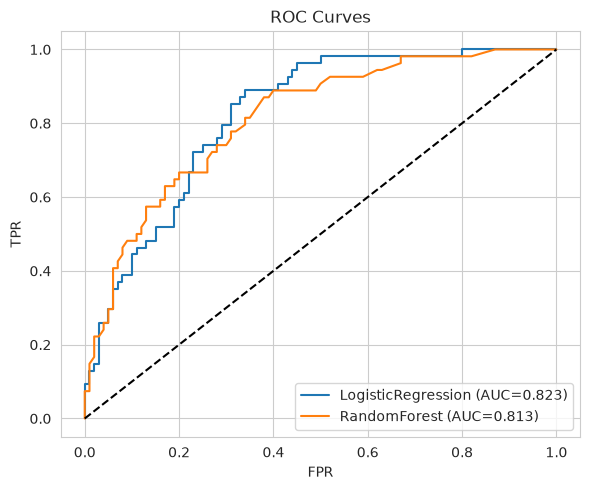

In [4]:
# ROC curves
plt.figure(figsize=(6,5))
for name, model in [("LogisticRegression", LogisticRegression(max_iter=1000)),
                    ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=42))]:
    model.fit(X_train, y_train)
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:,1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr,tpr):.3f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC Curves"); plt.legend()
plt.tight_layout(); plt.savefig("images/fig1_roc.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- Random Forest outperforms Logistic Regression on accuracy and F1.
- Recall matters most here: missing a diabetic patient is costlier than a false alarm.
- ROC-AUC confirms strong discriminative ability of both models.